# RF System and Receive Chain

**Part:** B – Hardware (deep dive) · **Reading time:** ~80 min · **Pass 1 overview:** [The MRI Scanner](../pass1_big_picture/P1.2_The_MRI_Scanner.ipynb) · **Refreshers you may want:** [Induction & RF (LC resonance, reciprocity)](../refreshers/RP2_Induction_and_RF.ipynb), [Complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [Fourier pairs & sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb)

**Why this chapter matters.** The RF system has two jobs with wildly different scales: on transmit it pushes **tens of kilowatts** into a coil to create a ~10 µT rotating field; on receive it must detect a signal of **nanovolts to microvolts** from the same body, adding as little noise as possible. Between the two sit resonant circuits, impedance matching, switches that protect microvolt preamplifiers from kilowatt pulses, and mixers/ADCs that turn a 128 MHz oscillation into the complex numbers of k-space. This chapter follows the signal through the whole chain, with the math (circuits, noise, demodulation) and Python demos for each step.

Related chapters: [B1 MRI System](../pass2_deep_dive/B1_MRI_System.ipynb) (overview), [B2 Magnetic Fields](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) (fields of coils, reciprocity), [E1 RF Pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb) (what the pulses do), [G2 SNR](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb), [H3 Accelerated Imaging](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb) (arrays for parallel imaging), [B6 Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb) (SAR limits).

## Learning goals

1. Trace the transmit chain (synthesizer → modulator → power amplifier → coil) and estimate the RF power needed for a pulse.
2. Explain the birdcage coil: its resonant modes (from a ladder-network model), the homogeneous mode, and why quadrature drive halves the power.
3. Treat a receive coil as an LC resonator: tuning, matching to 50 Ω, loaded vs unloaded Q, and body-noise dominance.
4. Compare surface and volume coils (sensitivity vs depth) and explain phased arrays: overlap decoupling and preamplifier decoupling.
5. Compute the noise figure of a receive chain with the Friis formula; explain T/R switching and active detuning with PIN diodes.
6. Demonstrate quadrature demodulation to complex baseband (= the rotating frame) and ADC sampling/quantization.
7. Compute thermal (Johnson) noise and estimate SNR from first principles.
8. Explain B1+ inhomogeneity at high field (wavelength in tissue), RF shimming/parallel transmit, the basics of SAR, and RF shielding.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $B_0$ | main static field | T | 1.5, 3, 7 T |
| $f_0=\bar\gamma B_0$, $\omega_0=2\pi f_0$ | Larmor frequency / angular frequency | Hz, rad/s | 63.9 MHz @1.5 T, 127.7 MHz @3 T, 298 MHz @7 T |
| $\gamma$, $\bar\gamma$ | gyromagnetic ratio (rad/s/T), gamma-bar (Hz/T) | | $\bar\gamma=42.58$ MHz/T |
| $b_1(t)$ | complex RF envelope in the rotating frame | T | |
| $B_1$ | amplitude of the RF field | T | 1–25 µT |
| $B_1^+$, $B_1^-$ | transmit (co-rotating) field component; receive sensitivity | T (per A for $B_1^-$) | |
| $\tilde B_x,\tilde B_y$ | complex phasor amplitudes of the RF field components | T | phasor convention $e^{+i\omega t}$ |
| $\theta$ | flip angle | rad | |
| $T_{rf}$ | RF pulse duration | s | 0.5–5 ms |
| $P$ | RF power | W | peak 15–35 kW |
| $L$, $C$, $R_{coil}$ | inductance, capacitance, resistance ($C$ ≠ coil sensitivity $C_n$!) | H, F, Ω | 100–300 nH, 1–100 pF, 0.5–5 Ω |
| $R_{sample}$, $R_{tot}$ | resistance representing losses in the body; total | Ω | |
| $Z$, $X$ | complex impedance; reactance (its imaginary part) | Ω | |
| $Z_0$ | characteristic impedance of cables / system reference | Ω | 50 Ω |
| $Z_{pre}$ | preamplifier input impedance | Ω | 1–2 Ω (low-impedance preamp) |
| $\Gamma$, $S_{11}$ | reflection coefficient; its value in dB | –, dB | |
| $Q$, $Q_U$, $Q_L$ | quality factor; unloaded / loaded | – | 200–400 / 20–80 |
| $f_{res}=1/(2\pi\sqrt{LC})$ | resonance frequency of an LC circuit | Hz | |
| $N_r$ | number of birdcage rungs | – | 16–32 |
| $L_r$, $L_e$, $C_r$, $C_e$ | rung and end-ring segment inductances and capacitances | H, F | |
| $m$ (mode index) | birdcage mode number | – | $m=1$: homogeneous mode |
| $J_n$, $I_n$ | mesh current / rung current $n$ | A | |
| $M$ | mutual inductance between two coils | H | zero at the right overlap |
| $a$ | loop radius | m | 2–15 cm |
| $d$ | depth below the coil / centre distance | m | |
| $F$, $NF=10\log_{10}F$ | noise factor; noise figure | –, dB | preamp NF ≈ 0.5 dB |
| $G_i$ | power gain of stage $i$ (linear) | – | |
| $T$ | absolute temperature (not tesla!) | K | 290–310 K |
| $k_B$ | Boltzmann constant | J/K | $1.381\times10^{-23}$ |
| $\Delta f$ | noise bandwidth | Hz | = receiver bandwidth |
| $v_n$ | rms thermal noise voltage | V | tens of nV |
| $s(t)$ | received signal (real RF voltage, or complex baseband) | V | |
| $\Delta f_{sp}$ | spin frequency offset from the reference | Hz | |
| $f_{ref}$ | demodulation reference frequency | Hz | $\approx f_0$ |
| $f_s$, $\Delta t$ | sampling rate; dwell time $\Delta t=1/f_s$ | Hz, s | |
| $BW_{read}$ | receiver bandwidth | Hz | ±16–±250 kHz |
| $N_{bits}$ | ADC resolution | bits | 14–18 |
| $M_0$ | equilibrium magnetization (here in physical units) | A/m | ≈ 0.01 A/m water @3 T |
| $N$ | spin density | m⁻³ | $6.7\times10^{28}$ |
| $V_{vox}$ | voxel volume | m³ | 1 mm³ = $10^{-9}$ |
| $T_{meas}$ | total sampling time | s | |
| $\varepsilon_r$, $\varepsilon_0$ | relative permittivity of tissue; vacuum permittivity | –, F/m | 50–80; $8.854\times10^{-12}$ |
| $\sigma_{el}$ | tissue conductivity | S/m | 0.5–0.8 |
| $k$ (wave) | complex wavenumber in tissue | rad/m | (not k-space here!) |
| $\lambda$ | wavelength | m | 2.35 m in air @3 T, ~25 cm in tissue |
| $c$ | speed of light | m/s | $3\times10^8$ |
| $\vec E$ | electric field | V/m | |
| $\rho$ | tissue mass density | kg/m³ | 1000 |
| $R_s$ | radius of the sphere in the SAR model | m | 0.1–0.2 |
| $SAR$ | specific absorption rate | W/kg | limits in [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb) |
| $\delta_s$ | skin depth | m | 6 µm in copper @128 MHz |
| $\mu_0$ | vacuum permeability | T m/A | $4\pi\times10^{-7}$ |
| $\mathbf w$ | complex channel weights in RF shimming | – | |

> **⚠️ Common confusion:** $C$ here is a capacitance, not the coil sensitivity $C_n(\vec r)$; $k$ is a wavenumber (rad/m), not a k-space coordinate; $T$ is temperature in kelvin. Engineers write $j$ for $\sqrt{-1}$; we write $i$.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. The chain at a glance

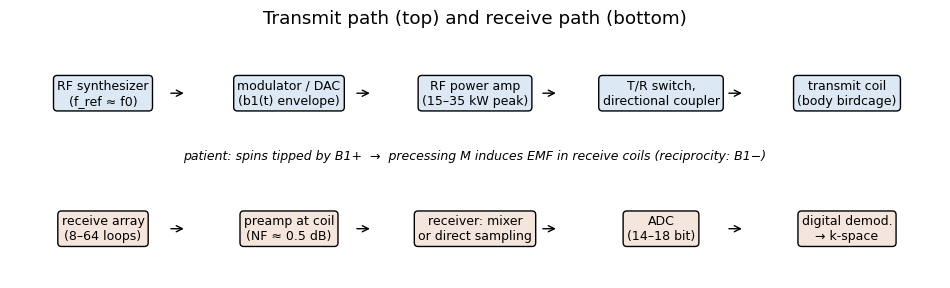

In [2]:
fig, ax = plt.subplots(figsize=(12, 3.2)); ax.axis("off"); ax.grid(False)
tx = ["RF synthesizer\n(f_ref ≈ f0)", "modulator / DAC\n(b1(t) envelope)", "RF power amp\n(15–35 kW peak)", "T/R switch,\ndirectional coupler", "transmit coil\n(body birdcage)"]
rx = ["receive array\n(8–64 loops)", "preamp at coil\n(NF ≈ 0.5 dB)", "receiver: mixer\nor direct sampling", "ADC\n(14–18 bit)", "digital demod.\n→ k-space"]
for row, items, y in [(0, tx, 0.75), (1, rx, 0.2)]:
    for i, txt in enumerate(items):
        ax.text(0.1 + i * 0.2, y, txt, ha="center", va="center", fontsize=9,
                bbox=dict(boxstyle="round", fc="#dde8f5" if row == 0 else "#f5e6dd"))
        if i < 4:
            ax.annotate("", xy=(0.19 + i * 0.2, y), xytext=(0.17 + i * 0.2, y), arrowprops=dict(arrowstyle="->"))
ax.text(0.5, 0.48, "patient: spins tipped by B1+  →  precessing M induces EMF in receive coils (reciprocity: B1−)", ha="center", fontsize=9, style="italic")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_title("Transmit path (top) and receive path (bottom)"); plt.show()

Everything in the RF chain is designed around the Larmor frequency $f_0=\bar\gamma B_0$: coils are tuned to it, amplifiers are optimized for a band around it, and the receiver removes it again (demodulation) to get the slowly varying complex signal we call k-space data.

## 2. Transmit side

### 2.1 Synthesizer, modulator and the lab-frame RF field

The pulse sequence describes the RF pulse by its **complex envelope** $b_1(t)=B_{1,x}(t)+iB_{1,y}(t)$ in the rotating frame ([E1 RF Pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb)). The hardware multiplies it onto a carrier at the reference frequency. With the clockwise (left-handed) precession convention of this course, the field that actually rotates *with* the spins is

$$B_x(t)+iB_y(t) = b_1(t)\,e^{-i\omega_{ref}t}.$$

In words: the lab-frame RF field is the rotating-frame envelope "spun" clockwise at the reference frequency; the synthesizer provides $e^{-i\omega_{ref}t}$, the modulator (today a fast DAC with digital upconversion) applies amplitude and phase.

where $\omega_{ref}=2\pi f_{ref}$ [rad/s] is the reference (carrier) angular frequency, chosen equal to the Larmor frequency of the slice of interest (slice offsets are frequency offsets, [E2](../pass2_deep_dive/E2_Slice_Selection.ipynb)).

### 2.2 How much power?

A rectangular pulse of duration $T_{rf}$ needs $B_1=\theta/(\gamma T_{rf})$ (`mt.b1_for_flip`). The power is proportional to $B_1^2$; we estimate the absorbed power with the SAR model of Section 7 (a uniform field in a conducting sphere).

In [3]:
for theta_deg, Trf in [(90, 1e-3), (180, 1e-3), (180, 3e-3)]:
    B1 = mt.b1_for_flip(np.deg2rad(theta_deg), Trf)
    print(f"{theta_deg:3d}° in {Trf*1e3:.0f} ms (hard pulse): B1 = {B1*1e6:5.2f} uT;  a sinc with the same area has ~3x the peak")

 90° in 1 ms (hard pulse): B1 =  5.87 uT;  a sinc with the same area has ~3x the peak
180° in 1 ms (hard pulse): B1 = 11.74 uT;  a sinc with the same area has ~3x the peak
180° in 3 ms (hard pulse): B1 =  3.91 uT;  a sinc with the same area has ~3x the peak


Power scales with $B_1^2$: a 180° sinc pulse with peak ~3× higher than the hard pulse needs ~9× the power. With an absorption of the order of 100 W/kg per (10 µT)² at 3 T in the body (Section 7) and some 30 kg of tissue in the coil, peak powers of **15–35 kW** are needed — hence the large amplifiers.

> **🔧 Engineering reality:** RF power amplifiers today are mostly solid-state (LDMOS transistors combined in parallel), rated for peak power (kW) and a lower average power (duty cycle ~5–10 %). Their output passes **directional couplers** that measure forward and reflected power for SAR supervision ([B6](../pass2_deep_dive/B6_MRI_Safety.ipynb)), then a T/R switch to the coil. The coil "loading" by the patient changes from person to person, so prescan measures the transmit voltage needed for a given flip angle (Section 2.5).

### 2.3 The birdcage coil

![Birdcage schematic: rungs parallel to B0 connected by two end rings with capacitors](../images/Birdcage_schematic.png)

![A whole-body birdcage coil (copper rungs and end rings with capacitors on a fibreglass former)](../images/BODY_coil.png)

A birdcage consists of $N_r$ straight **rungs** parallel to $B_0$, joined by two **end rings**. Capacitors sit in the rungs (**low-pass** birdcage), in the end-ring segments (**high-pass**), or both (band-pass). Electrically it is a periodic **ladder network** closed into a ring: each "mesh" is formed by two neighbouring rungs and the end-ring segments between them.

**Mesh analysis.** Let $J_n$ be the current circulating in mesh $n$; rung $n$ then carries $I_n=J_n-J_{n-1}$. Kirchhoff's voltage law around every mesh gives a matrix equation $\big(i\omega\mathbf L+\frac{1}{i\omega}\mathbf S\big)\mathbf J=\mathbf 0$, i.e. the generalized eigenvalue problem

$$\mathbf S\,\mathbf J=\omega^2\,\mathbf L\,\mathbf J,$$

In words: the coil resonates only at frequencies where a pattern of mesh currents makes the inductive and capacitive voltages cancel around every mesh; these patterns are the eigenvectors, and $\omega^2$ are the eigenvalues.

where $\mathbf L$ [H] is the mesh inductance matrix (diagonal $2L_e+2L_r$, neighbours $-L_r$; mutual inductances ignored), and $\mathbf S$ [1/F] the inverse-capacitance ("elastance") matrix (diagonal $2/C_e+2/C_r$, neighbours $-1/C_r$). Both matrices are circulant (the ring is symmetric), so the eigenvectors are discrete Fourier modes $J_n\propto e^{i2\pi mn/N_r}$ — the rung currents vary as $\cos(2\pi mn/N_r+\phi)$. For the high-pass design this gives

$$\omega_m=\frac{1}{\sqrt{C_e\big(L_e+2L_r\sin^2(\pi m/N_r)\big)}} .$$

In words: each mode number $m$ has its own resonance frequency; the $m=1$ mode, whose rung currents vary as $\cos\varphi$ around the cage, produces a uniform transverse field — that is the one we tune to $f_0$.

In [4]:
from scipy.linalg import eigh

def circulant(diag, off, n):
    M = np.diag(np.full(n, float(diag)))
    for j in range(n):
        M[j, (j + 1) % n] += off; M[j, (j - 1) % n] += off
    return M

Nr, Lr, Le = 16, 300e-9, 40e-9          # rungs, rung and end-ring-segment inductance (illustrative body coil)
f0 = mt.larmor_frequency(3.0); w0 = 2 * np.pi * f0
s2 = np.sin(np.pi / Nr) ** 2
Ce = 1 / (w0**2 * (Le + 2 * Lr * s2))   # high-pass: choose end-ring capacitors so that mode m=1 sits at f0
Lmat = circulant(2 * Le + 2 * Lr, -Lr, Nr)
Smat = np.diag(np.full(Nr, 2 / Ce))
w2, Jmodes = eigh(Smat, Lmat)
f_modes = np.sqrt(w2) / (2 * np.pi)
print(f"end-ring capacitors C_e = {Ce*1e12:.1f} pF;  mode frequencies [MHz]:", np.round(np.sort(f_modes) / 1e6, 1))

end-ring capacitors C_e = 24.7 pF;  mode frequencies [MHz]: [ 40.   40.8  40.8  43.1  43.1  47.5  47.5  54.9  54.9  67.5  67.5  89.5
  89.5 127.7 127.7 160.1]


The modes come in degenerate pairs (cos and sin patterns), except $m=0$ (end-ring mode, highest frequency for high-pass) and $m=N_r/2$. Now the field of a mode: treat the rungs as long straight wires at angle $\varphi_n$ on a cylinder (2D, quasi-static: $\vec B=\frac{\mu_0 I}{2\pi\rho}\hat\varphi$ around each wire).

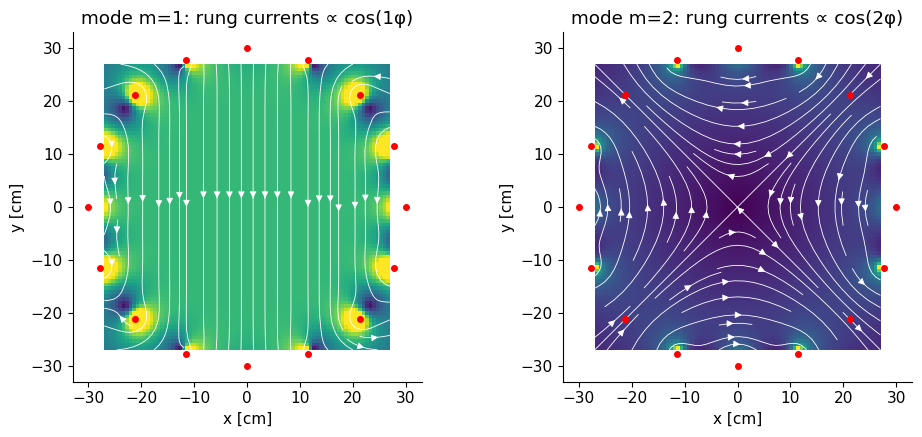

In [5]:
R_bc = 0.30
phi_r = 2 * np.pi * np.arange(Nr) / Nr
xg, yg = np.meshgrid(np.linspace(-0.27, 0.27, 81), np.linspace(-0.27, 0.27, 81))

def rung_field(I_rungs):
    Bx = np.zeros_like(xg, dtype=complex); By = np.zeros_like(Bx)
    for I, ph in zip(I_rungs, phi_r):
        dx, dy = xg - R_bc * np.cos(ph), yg - R_bc * np.sin(ph)
        r2 = dx**2 + dy**2
        Bx += mt.MU0 * I / (2 * np.pi) * (-dy) / r2; By += mt.MU0 * I / (2 * np.pi) * dx / r2
    return Bx, By

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for axi, m in zip(ax, (1, 2)):
    Bx, By = rung_field(np.cos(m * phi_r))
    Bm = np.hypot(Bx.real, By.real)
    axi.imshow(Bm / Bm[40, 40] if m == 1 else Bm / Bm.max(), extent=[-27, 27, -27, 27], origin="lower", vmin=0, vmax=1.5 if m == 1 else 1)
    axi.streamplot(xg[0] * 100, yg[:, 0] * 100, Bx.real, By.real, color="w", density=0.8, linewidth=0.6)
    axi.plot(R_bc * 100 * np.cos(phi_r), R_bc * 100 * np.sin(phi_r), "ro", ms=4)
    axi.set(title=f"mode m={m}: rung currents ∝ cos({m}φ)", xlabel="x [cm]", ylabel="y [cm]"); axi.grid(False)
plt.tight_layout(); plt.show()

Mode $m=1$ gives a nearly uniform field across the cage (left) — the reason the birdcage is the standard body and head transmit coil. Mode $m=2$ produces a quadrupolar (gradient-like) pattern and is useless for excitation.

**Quadrature drive.** The $m=1$ mode exists twice (cos and sin patterns, fields along $x$ and $y$). Feeding both ports with signals 90° apart makes the field **rotate**. A linearly polarized field $B\cos\omega t\,\hat x$ is the sum of two counter-rotating fields of amplitude $B/2$; only the one rotating with the spins ($B_1^+$) tips them. Quadrature drive puts all the field into $B_1^+$: same $B_1^+$ at **half the power** (and on receive, √2 better SNR).

In [6]:
t = np.linspace(0, 2 / f0, 400)
lin = np.cos(w0 * t) + 0j                                   # B_x only (linear drive, amplitude 1)
quad = np.cos(w0 * t) - 1j * np.sin(w0 * t)                 # B_x + i B_y rotating clockwise, amplitude 1
for name, b in [("linear (one port, I)", lin), ("quadrature (two ports, I each)", quad)]:
    co = np.mean(b * np.exp(+1j * w0 * t))                   # component rotating with the spins (e^{-i w t})
    counter = np.mean(b * np.exp(-1j * w0 * t))
    print(f"{name:32s} |B1+| = {abs(co):.2f}, |B1-rotating the wrong way| = {abs(counter):.2f}")
print("linear drive needs current 2I (power 4P) for |B1+| = 1; quadrature needs 2 ports x P = 2P -> factor 2 saving")

linear (one port, I)             |B1+| = 0.50, |B1-rotating the wrong way| = 0.50
quadrature (two ports, I each)   |B1+| = 1.00, |B1-rotating the wrong way| = 0.00
linear drive needs current 2I (power 4P) for |B1+| = 1; quadrature needs 2 ports x P = 2P -> factor 2 saving


> **TODO (polish):** add the low-pass/band-pass mode spectra, mutual inductances between rungs, and an end-ring "ladder" schematic figure.

### 2.4 Reciprocity: one map for transmit and receive

By the **reciprocity principle** ([Induction & RF](../refreshers/RP2_Induction_and_RF.ipynb), [B2](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb)), the voltage a precessing magnetization induces in a coil is proportional to the field that coil would produce per unit current at that location: $B_1^-(\vec r)$. The same coil maps describe transmit ($B_1^+$, co-rotating part) and receive ($B_1^-$, counter-rotating part of the coil's own field, because receive looks "backwards" in time). At low field $|B_1^+|\approx|B_1^-|$; at high field they differ (Section 6).

### 2.5 Transmit calibration

Every patient loads the coil differently, so the scanner calibrates the transmit voltage that gives the nominal flip angle (e.g. by finding the voltage that nulls the signal of a 180° pulse), and can map $B_1^+$. One classic mapping method is the **double-angle method**: acquire images with $\theta$ and $2\theta$ (long TR); since $S\propto\sin\theta$, $\theta(\vec r)=\arccos\big(S_{2\theta}/(2S_\theta)\big)$.

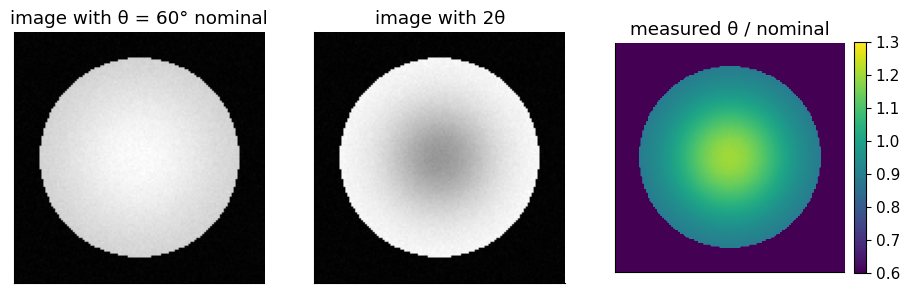

In [7]:
N = 128
yy, xx = np.mgrid[-1:1:N * 1j, -1:1:N * 1j]
obj = (xx**2 + yy**2 < 0.8**2).astype(float)
b1_rel = 1 + 0.35 * np.exp(-(xx**2 + yy**2) / 0.3) - 0.15          # a centre-bright B1+ map (relative)
theta_nom = np.deg2rad(60)
S1 = mt.add_complex_noise(obj * np.sin(theta_nom * b1_rel), 0.01)
S2 = mt.add_complex_noise(obj * np.sin(2 * theta_nom * b1_rel), 0.01)
theta_map = np.arccos(np.clip(np.real(S2 / np.where(obj > 0, S1, 1)) / 2, -1, 1)) * obj
fig, ax = plt.subplots(1, 3, figsize=(11, 3.5))
mt.show_image(S1, ax[0], "image with θ = 60° nominal")
mt.show_image(S2, ax[1], "image with 2θ")
im = mt.show_image(np.rad2deg(theta_map) / 60 * obj, ax[2], "measured θ / nominal", cmap="viridis", vmin=0.6, vmax=1.3, colorbar=True)
plt.show()

The ratio map recovers the relative $B_1^+$ (here up to 1.2× in the centre), which the scanner can use for calibration, RF shimming, or quantitative corrections (e.g. T1 mapping).

## 3. Receive coils: resonant circuits

### 3.1 Tuning: the coil as an LC resonator

A receive loop is an inductor $L$ (the loop), broken by capacitors $C$, with a small series resistance $R_{tot}$. Its impedance is

$$Z(\omega)=R_{tot}+i\omega L+\frac{1}{i\omega C},$$

In words: the inductive reactance grows with frequency, the capacitive one shrinks; at one frequency they cancel and only the resistance remains — resonance, where a given induced voltage drives the largest current.

where $\omega$ [rad/s] is the angular frequency. Resonance: $\omega_{res}=1/\sqrt{LC}$. The **quality factor** $Q=\omega_0L/R_{tot}$ measures how sharp the resonance is (bandwidth ≈ $f_0/Q$).

10 cm loop: L = 251 nH, reactance wL = 201 Ohm at 127.7 MHz; tuning C = 6.19 pF
Q_U = 300: R_coil = 0.67 Ohm;  Q_L = 40: R_tot = 5.03 Ohm -> body resistance 4.36 Ohm
fraction of noise power from the body: 87 %  (= 1 - Q_L/Q_U)


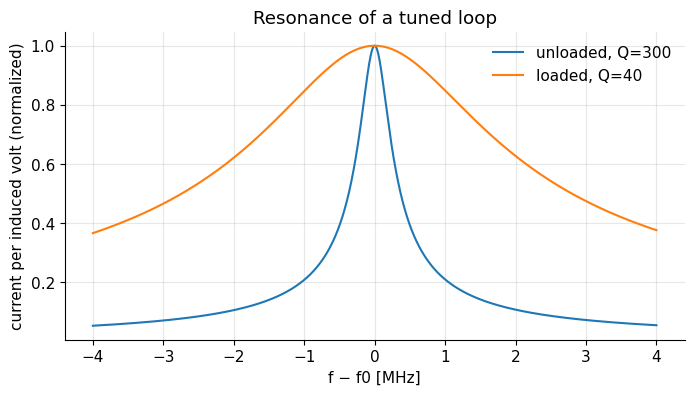

In [8]:
a_loop, b_wire = 0.05, 1e-3                  # loop radius and wire radius [m]
L_loop = mt.MU0 * a_loop * (np.log(8 * a_loop / b_wire) - 2)    # standard thin-wire loop inductance formula
C_tune = 1 / (w0**2 * L_loop)
print(f"10 cm loop: L = {L_loop*1e9:.0f} nH, reactance wL = {w0*L_loop:.0f} Ohm at {f0/1e6:.1f} MHz; tuning C = {C_tune*1e12:.2f} pF")
QU, QL = 300, 40
R_coil = w0 * L_loop / QU; R_tot = w0 * L_loop / QL; R_sample = R_tot - R_coil
print(f"Q_U = {QU}: R_coil = {R_coil:.2f} Ohm;  Q_L = {QL}: R_tot = {R_tot:.2f} Ohm -> body resistance {R_sample:.2f} Ohm")
print(f"fraction of noise power from the body: {R_sample/R_tot*100:.0f} %  (= 1 - Q_L/Q_U)")
f = np.linspace(f0 - 4e6, f0 + 4e6, 2000); w = 2 * np.pi * f
for Rt, lab in [(R_coil, f"unloaded, Q={QU}"), (R_tot, f"loaded, Q={QL}")]:
    I = 1 / np.abs(Rt + 1j * w * L_loop + 1 / (1j * w * C_tune))
    plt.plot((f - f0) / 1e6, I / I.max(), label=lab)
plt.xlabel("f − f0 [MHz]"); plt.ylabel("current per induced volt (normalized)"); plt.legend(); plt.title("Resonance of a tuned loop"); plt.show()

Unloaded the loop is very sharp (bandwidth ~0.4 MHz); with a patient the body's conductive losses broaden it 7-fold. Because ~85 % of the noise then comes from the body, better copper or cooling the coil gains little — the regime called **body-noise dominance** (typical above ~1 T for coils larger than a few cm). Small coils and low fields can be coil-noise dominated, where cooled or superconducting coils help.

> **🔧 Engineering reality:** The capacitance is split into several capacitors around the loop. This keeps the electric fields (and thus dielectric losses in the patient and the frequency shift caused by the patient's permittivity) low. Capacitors must be non-magnetic and handle the induced voltages.

### 3.2 Matching to 50 Ω

The cable and preamplifier are built around $Z_0=50$ Ω. The coil at resonance looks like a few ohms. **Why match?** (i) A cable terminated in its characteristic impedance carries the signal without reflections; (ii) low-noise preamps reach their minimum noise figure for a specific source impedance (typically 50 Ω); (iii) on transmit, matched coils accept the power instead of reflecting it.

A simple network: capacitor $C_t$ in series in the loop with the port across it, and a series inductor $L_m$ to the cable. With $\omega L_m = 1/(\omega C_t) = X_t$ and the loop tuned, the input impedance is

$$Z_{in}=\frac{X_t^2}{R_{tot}}\quad\Rightarrow\quad X_t=\sqrt{Z_0R_{tot}} .$$

In words: the capacitor–inductor pair works as an impedance transformer; choosing the reactance as the geometric mean of 50 Ω and the coil resistance turns a few ohms into 50 Ω.

where $X_t$ [Ω] is the reactance of $C_t$ and $L_m$.

<details><summary><b>📐 Derivation (optional)</b></summary>

Let the rest of the loop be $Z_r=R_{tot}+iX_r$. Looking into the port, $Z_r$ is in parallel with $C_t$ (impedance $-iX_t$), then $L_m$ ($+iX_t$) in series:
$Z_{in}=\frac{Z_r(-iX_t)}{Z_r-iX_t}+iX_t=\frac{-iX_tZ_r+iX_tZ_r+X_t^2}{Z_r-iX_t}=\frac{X_t^2}{R_{tot}+i(X_r-X_t)}$. The loop is tuned when the total loop reactance $X_r-X_t$ vanishes, leaving $Z_{in}=X_t^2/R_{tot}$.

</details>

C_t = 78.6 pF, L_m = 19.8 nH, distributed loop capacitance C_s = 6.72 pF


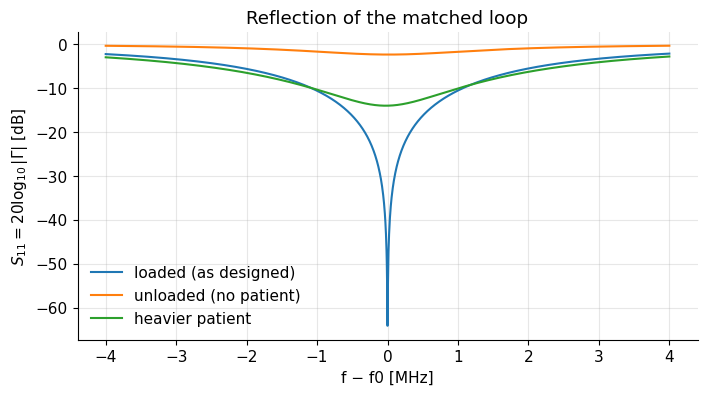

In [9]:
Z0 = 50.0
Xt = np.sqrt(Z0 * R_tot)
Ct = 1 / (w0 * Xt); Lm = Xt / w0
Cs = 1 / (w0 * (w0 * L_loop - Xt))                 # remaining loop capacitance so that the whole loop is tuned
print(f"C_t = {Ct*1e12:.1f} pF, L_m = {Lm*1e9:.1f} nH, distributed loop capacitance C_s = {Cs*1e12:.2f} pF")

def Z_in(w, Rt, Zload_side=None):
    Zr = Rt + 1j * w * L_loop + 1 / (1j * w * Cs)
    Zct = 1 / (1j * w * Ct)
    return Zr * Zct / (Zr + Zct) + 1j * w * Lm

for Rt, lab in [(R_tot, "loaded (as designed)"), (R_coil, "unloaded (no patient)"), (1.5 * R_tot, "heavier patient")]:
    Gam = (Z_in(w, Rt) - Z0) / (Z_in(w, Rt) + Z0)
    plt.plot((f - f0) / 1e6, 20 * np.log10(np.abs(Gam)), label=lab)
plt.xlabel("f − f0 [MHz]"); plt.ylabel(r"$S_{11}=20\log_{10}|\Gamma|$ [dB]"); plt.legend(); plt.title("Reflection of the matched loop"); plt.show()

A deep dip (< −20 dB) means well matched. Without the patient the same coil is badly mismatched; a heavier load shifts it moderately — receive arrays are designed so that typical loads stay acceptably matched (and the preamp's noise figure is fairly tolerant).

## 4. Surface coils, volume coils and phased arrays

### 4.1 Sensitivity vs depth

On the axis of a loop of radius $a$, the field per ampere is $B=\mu_0a^2/(2(a^2+d^2)^{3/2})$ (`mt.loop_field_on_axis`). In the body-noise-dominated regime, the noise resistance of a loop over a conducting body grows roughly as $a^3$, so the noise voltage grows as $a^{3/2}$ and

$$SNR(d)\propto\frac{a^2}{(a^2+d^2)^{3/2}\,a^{3/2}}\quad\Rightarrow\quad a_{opt}=\frac{d}{\sqrt5}.$$

In words: small loops are very sensitive close to the surface but fall off quickly; for a target at depth $d$ the best loop radius is about $0.45\,d$.

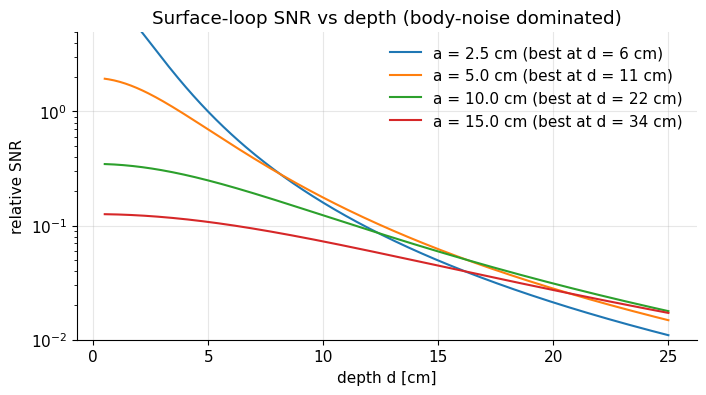

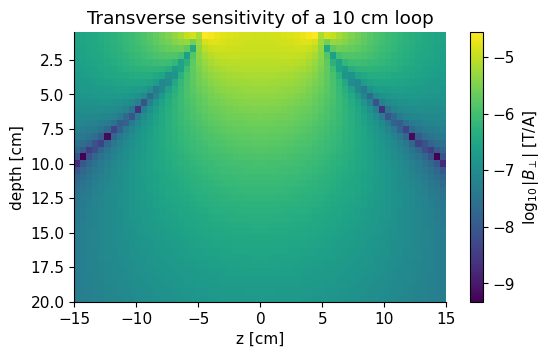

In [10]:
d = np.linspace(0.005, 0.25, 300)
for a_ in (0.025, 0.05, 0.10, 0.15):
    snr = mt.loop_field_on_axis(d, a_, 1.0) / a_**1.5
    plt.plot(d * 100, snr / (mt.loop_field_on_axis(0.05, 0.05 * np.sqrt(5) / 5, 1.0) / (0.05 / np.sqrt(5)) ** 1.5), label=f"a = {a_*100:.1f} cm (best at d = {a_*np.sqrt(5)*100:.0f} cm)")
plt.yscale("log"); plt.ylim(1e-2, 5); plt.xlabel("depth d [cm]"); plt.ylabel("relative SNR"); plt.legend(); plt.title("Surface-loop SNR vs depth (body-noise dominated)"); plt.show()

# 2D map of the transverse field of a loop lying on the patient's back (normal along y, B0 along z)
zz2, yy2 = np.meshgrid(np.linspace(-0.15, 0.15, 61), np.linspace(0.005, 0.2, 40))
pts = np.stack([0 * zz2, yy2, zz2], -1)
B = mt.loop_coil_field(pts, 0.05, 1.0, normal="y")
plt.figure(figsize=(6, 3.5)); plt.imshow(np.log10(np.hypot(B[..., 0], B[..., 1])), extent=[-15, 15, 20, 0.5], aspect="auto")
plt.colorbar(label=r"$\log_{10}|B_\perp|$ [T/A]"); plt.xlabel("z [cm]"); plt.ylabel("depth [cm]"); plt.title("Transverse sensitivity of a 10 cm loop"); plt.grid(False); plt.show()

Only the field components perpendicular to $B_0$ ($B_x$, $B_y$) count for MR. Volume coils (birdcages) give uniform but lower sensitivity; arrays of small loops combine the surface coil's SNR with coverage.

### 4.2 Phased arrays

![Separate images of the four elements of a lumbar spine array and their combination](../images/SpineArray.png)

![A modern scanner with many receive arrays placed around the body and in the table](../images/TIM_receive_array.png)

Each element sees mostly its own neighbourhood (above). The challenge: neighbouring resonant loops couple through their **mutual inductance** $M$; coupled resonators split into two resonances, detune each other and share noise. Two remedies:

1. **Overlap decoupling:** overlap neighbours so that the flux of one through the other cancels ($M=0$). For circular loops this happens at a centre distance of ≈1.5$a$ (computed below with Neumann's formula $M=\frac{\mu_0}{4\pi}\oint\oint\frac{d\vec\ell_1\cdot d\vec\ell_2}{|\vec r_1-\vec r_2|}$).
2. **Preamplifier decoupling** (for non-neighbours): use a preamp with very low input impedance $Z_{pre}$ (~2 Ω). Through the match network ($C_t$ and $L_m$ now form a parallel resonance), the loop sees a large series impedance $\approx X_t^2/Z_{pre}=Z_0R_{tot}/Z_{pre}$, so hardly any current flows — and without current there is no coupling — while the preamp still sees a 50 Ω source and keeps its low noise figure.

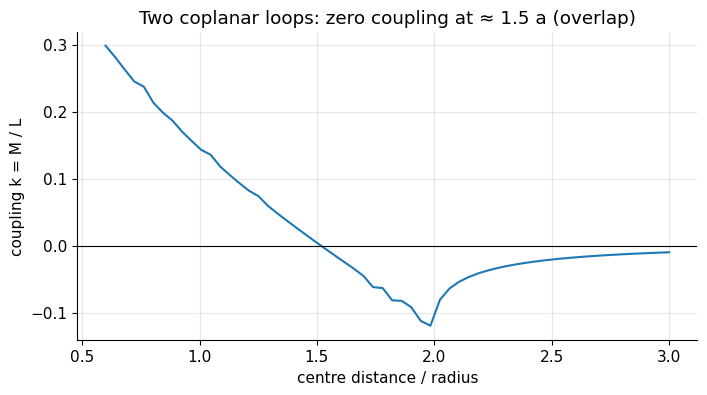

blocking impedance with preamp decoupling (Z_pre = 2 Ohm): 126 Ohm vs loop resistance 5.0 Ohm -> current suppression 28 dB


In [11]:
def loop_segments(a, cx, n=200):
    ph = np.linspace(0, 2 * np.pi, n + 1)
    P = np.stack([cx + a * np.cos(ph), a * np.sin(ph), 0 * ph], -1)
    return 0.5 * (P[1:] + P[:-1]), P[1:] - P[:-1]

def mutual_inductance(a, dist):
    m1, d1 = loop_segments(a, 0.0); m2, d2 = loop_segments(a, dist)
    R = np.linalg.norm(m1[:, None] - m2[None], axis=-1)
    return mt.MU0 / (4 * np.pi) * np.sum((d1 @ d2.T) / np.maximum(R, 1e-4))

dist = np.linspace(0.6, 3, 60) * a_loop
Mv = np.array([mutual_inductance(a_loop, x_) for x_ in dist])
plt.plot(dist / a_loop, Mv / L_loop); plt.axhline(0, color="k", lw=0.8)
plt.xlabel("centre distance / radius"); plt.ylabel("coupling k = M / L"); plt.title("Two coplanar loops: zero coupling at ≈ 1.5 a (overlap)"); plt.show()
print(f"blocking impedance with preamp decoupling (Z_pre = 2 Ohm): {Z0*R_tot/2:.0f} Ohm vs loop resistance {R_tot:.1f} Ohm "
      f"-> current suppression {20*np.log10(Z0*R_tot/2/R_tot):.0f} dB")

> **TODO (polish):** add a two-coupled-loop circuit simulation showing resonance splitting without decoupling and its removal by preamp decoupling; add noise-correlation matrix and optimal (Roemer) combination (see [J4 Advanced SNR](../pass2_deep_dive/J4_Advanced_SNR.ipynb)).

## 5. Preamplifier, noise figure, T/R switching

### 5.1 Noise figure and the Friis formula

The **noise factor** $F=SNR_{in}/SNR_{out}\ge1$ tells how much a stage degrades SNR; the noise figure is $NF=10\log_{10}F$ [dB]. For a chain of stages with power gains $G_i$:

$$F_{tot}=F_1+\frac{F_2-1}{G_1}+\frac{F_3-1}{G_1G_2}+\dots$$

In words: the first stage's noise counts fully; later stages' noise is divided by the gain in front of them. So put a low-noise, high-gain amplifier **first** — right at the coil, before any cable loss.

where a lossy cable with loss factor $L_{loss}$ has $F=L_{loss}$ and $G=1/L_{loss}$.

In [12]:
def db2lin(x): return 10 ** (x / 10)
def friis(stages):
    """stages: list of (NF_dB, gain_dB). Returns total NF in dB."""
    F, G = 0.0, 1.0
    for i, (nf, g) in enumerate(stages):
        F += db2lin(nf) if i == 0 else (db2lin(nf) - 1) / G
        G *= db2lin(g)
    return 10 * np.log10(F)
preamp, cable, amp2, adc = (0.5, 28), (3, -3), (4, 20), (25, 0)
print(f"preamp at coil -> cable -> amp -> ADC : NF = {friis([preamp, cable, amp2, adc]):.2f} dB")
print(f"cable first  -> preamp -> amp -> ADC : NF = {friis([cable, preamp, amp2, adc]):.2f} dB")
print(f"without preamp (cable -> amp -> ADC) : NF = {friis([cable, amp2, adc]):.2f} dB")

preamp at coil -> cable -> amp -> ADC : NF = 0.56 dB
cable first  -> preamp -> amp -> ADC : NF = 3.53 dB
without preamp (cable -> amp -> ADC) : NF = 10.53 dB


With the preamp at the coil the chain adds only ~0.6 dB (≈7 % SNR loss); putting 3 dB of cable in front costs 3.5 dB (a third of the SNR). This is why every receive element has its own preamp in the coil housing.

### 5.2 T/R switching and active detuning (PIN diodes)

During transmit, the body coil produces ~10 µT at $f_0$. A *tuned* receive loop would pick up a huge EMF $=\omega_0B_1A$ and, being resonant, carry a large current: it would distort $B_1^+$, heat the patient and destroy its preamp.

In [13]:
A_loop = np.pi * a_loop**2
emf = w0 * 10e-6 * A_loop
print(f"EMF in a 10 cm loop from a 10 uT transmit field at 3 T: {emf:.0f} V (peak)")
print(f"current if the loop stays tuned (R = {R_tot:.1f} Ohm): {emf/R_tot:.0f} A;  detuned by a 1 kOhm trap: {emf/1000*1e3:.0f} mA")

EMF in a 10 cm loop from a 10 uT transmit field at 3 T: 63 V (peak)
current if the loop stays tuned (R = 5.0 Ohm): 13 A;  detuned by a 1 kOhm trap: 63 mA


Therefore each receive loop contains a **detuning trap**: an inductor switched in parallel with one of the tuning capacitors by a **PIN diode**. Forward-biased with a DC current (~100 mA) the diode conducts and the L–C pair forms a parallel resonance at $f_0$ (impedance of kΩ) that blocks the loop; reverse-biased the diode is open and the loop is tuned. Passive back-up (crossed diodes that conduct on large induced voltages, fuses) protects against bias failure. Conversely the body coil is detuned during receive, and transmit/receive coils use a **T/R switch** (PIN diodes plus quarter-wave lines) that routes kW to the coil and the µV signal to the preamp.

## 6. From RF to numbers: demodulation and the ADC

### 6.1 Quadrature demodulation = moving into the rotating frame

The coil voltage is real: $s(t)=\mathrm{Re}\{m\,e^{-i(\omega_{ref}+2\pi\Delta f_{sp})t}\}$, where $m$ is the complex transverse magnetization amplitude (rotating frame) and $\Delta f_{sp}$ the spin's offset from the reference. Multiplying by $2e^{+i\omega_{ref}t}=2\cos\omega_{ref}t+2i\sin\omega_{ref}t$ gives

$$2s(t)e^{i\omega_{ref}t}=m\,e^{-i2\pi\Delta f_{sp}t}+m^*e^{+i(2\omega_{ref}+2\pi\Delta f_{sp})t}.$$

In words: mixing with the reference shifts the signal down to near zero frequency (the rotating-frame signal, which is what we want) plus a copy at twice the carrier frequency, which a low-pass filter removes.

where $m^*$ is the complex conjugate. The two real multiplications (with cos and with sin) are the **I** (in-phase) and **Q** (quadrature) channels; together they form one complex number per sample. Mathematically this *is* the transformation to the rotating frame ([A2 Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb)).

Simulation at 1.5 T (64 MHz carrier, sampled at 1 GHz "analog" rate), three spins at −3, +1 and +5 kHz:

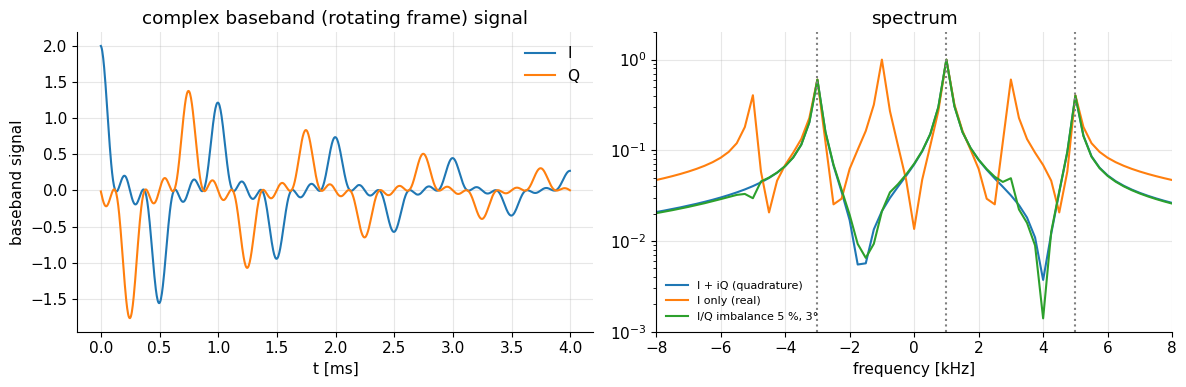

In [14]:
fc = 63.86e6; fs_an = 1.0e9; Tsig = 4e-3
t = np.arange(int(Tsig * fs_an)) / fs_an
spins = [(-3e3, 0.6), (1e3, 1.0), (5e3, 0.4)]               # (offset [Hz], amplitude)
T2s = 2e-3
s_rf = sum(A * np.cos(2 * np.pi * (fc + df) * t) for df, A in spins) * np.exp(-t / T2s)   # Re{A e^{-i(w+dw)t}}
def lowpass_decimate(x, n):   # block average = simple low-pass filter + decimation
    return x[: len(x) // n * n].reshape(-1, n).mean(1)
mix = 2 * s_rf * np.exp(1j * 2 * np.pi * fc * t)
bb = lowpass_decimate(mix, 1000)                         # 1 MHz rate: the 2*fc term averages out
bb = lowpass_decimate(bb, 4); dt_bb = 4e-6               # dwell 4 us -> BW 250 kHz
I_only = lowpass_decimate(lowpass_decimate(2 * s_rf * np.cos(2 * np.pi * fc * t), 1000), 4)  # real channel only
gain_err, ph_err = 0.05, np.deg2rad(3)
bb_imb = bb.real + 1j * (1 + gain_err) * (bb.imag * np.cos(ph_err) + bb.real * np.sin(ph_err))   # I/Q imbalance
del mix, s_rf

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tb = np.arange(len(bb)) * dt_bb
ax[0].plot(tb * 1e3, bb.real, label="I"); ax[0].plot(tb * 1e3, bb.imag, label="Q")
ax[0].set(xlabel="t [ms]", ylabel="baseband signal", title="complex baseband (rotating frame) signal"); ax[0].legend()
freqs = (np.arange(len(bb)) - len(bb) // 2) / (len(bb) * dt_bb)
for x_, lab in [(bb, "I + iQ (quadrature)"), (I_only, "I only (real)"), (bb_imb, "I/Q imbalance 5 %, 3°")]:
    spec = np.abs(mt.ifftc(x_))          # inverse DFT: with clockwise precession this puts +Δf at +f
    ax[1].semilogy(freqs / 1e3, spec / spec.max() + 1e-6, label=lab)
ax[1].set(xlim=(-8, 8), ylim=(1e-3, 2), xlabel="frequency [kHz]", title="spectrum"); ax[1].legend(fontsize=8)
for df, A in spins: ax[1].axvline(df / 1e3, color="gray", ls=":")
plt.tight_layout(); plt.show()

With I and Q the three spins appear at their correct signed offsets (dotted lines). A single real channel cannot tell +1 kHz from −1 kHz: every peak gets a mirror twin. An I/Q gain/phase imbalance leaves small mirror peaks ("quadrature ghosts"); digital receivers avoid analog imbalance altogether.

> **📐 Math note:** We display the spectrum with the *inverse* DFT. Because precession is clockwise, $m\,e^{-i2\pi\Delta f t}$ — exactly the k-space signal model $s(t)=\int m(x)e^{-i2\pi k(t)x}dx$, which we also invert with the inverse FT.

### 6.2 The ADC: sampling, bandwidth and dynamic range

- **Sampling:** the dwell time $\Delta t$ sets the receiver bandwidth $BW_{read}=1/\Delta t$ and thus the FOV in the readout direction ([G1 FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb)); an anti-alias filter must remove noise outside it.
- **Dynamic range:** an ideal $N_{bits}$ ADC has a quantization SNR of $6.02N_{bits}+1.76$ dB. The k-space centre can be 60–100 dB above the noise (3D, large FOV), so the receiver gain is set in prescan so that the peak just fits (overflow → artifacts, [I2](../pass2_deep_dive/I2_Artifacts.ipynb)) while thermal noise still spans several LSBs.

k-space dynamic range: peak / noise = 76 dB


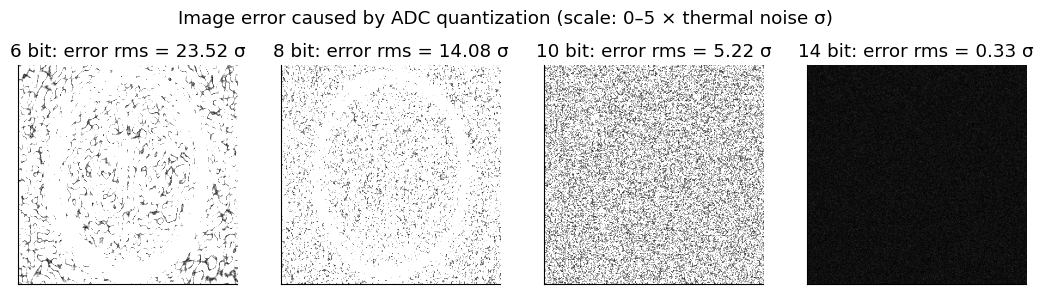

In [15]:
img = mt.shepp_logan(256)
K = mt.fft2c(img)
sigma = 0.01 * np.abs(img).max() / 2      # noise per k-space sample giving image SNR ~ 100
Kn = mt.add_complex_noise(K, sigma)
print(f"k-space dynamic range: peak / noise = {20*np.log10(np.abs(Kn).max()/sigma):.0f} dB")
def quantize(x, nbits, full_scale):
    q = full_scale / 2 ** (nbits - 1)
    f_ = lambda v: np.clip(np.round(v / q), -2 ** (nbits - 1), 2 ** (nbits - 1) - 1) * q
    return f_(x.real) + 1j * f_(x.imag)
fs_ = 1.05 * np.abs(Kn).max()
fig, ax = plt.subplots(1, 4, figsize=(13, 3.4))
for axi, nb in zip(ax, (6, 8, 10, 14)):
    err = mt.ifft2c(quantize(Kn, nb, fs_)) - mt.ifft2c(Kn)
    mt.show_image(np.abs(err), axi, f"{nb} bit: error rms = {np.sqrt(np.mean(np.abs(err)**2))/sigma:.2f} σ", vmin=0, vmax=5 * sigma)
plt.suptitle("Image error caused by ADC quantization (scale: 0–5 × thermal noise σ)"); plt.show()

Below ~10 bits the quantization error exceeds the thermal noise and adds structured artifacts; with 14 bits it is negligible. Modern receivers use 16–18-bit ADCs and often **direct RF sampling** (digitizing the 64–300 MHz signal itself, using bandpass sampling: a 127.7 MHz signal sampled at 100 MS/s aliases to 27.7 MHz), with mixing and filtering done digitally — sometimes right in the coil, sending data over optical fibre.

## 7. Noise and SNR from first principles

Every resistor at temperature $T$ generates **thermal (Johnson) noise** with rms voltage

$$v_n=\sqrt{4k_BTR_{tot}\Delta f},$$

In words: random thermal motion of charges in any lossy conductor — including the patient's tissue — produces a noise voltage that grows with temperature, resistance and the bandwidth you listen to.

where $k_B$ [J/K] is the Boltzmann constant, $T$ [K] the temperature, $R_{tot}$ [Ω] the total loss resistance, $\Delta f$ [Hz] the bandwidth. The signal EMF of a voxel follows from reciprocity: $\text{EMF}=\omega_0\,|B_1^-|\,M_0V_{vox}$ with $M_0=N\gamma^2\hbar^2B_0/(4k_BT)$.

In [16]:
T_body, B0 = 310.0, 3.0
v_n = np.sqrt(4 * mt.K_BOLTZMANN * T_body * R_tot * 100e3)
M0 = 6.7e28 * mt.GAMMA**2 * mt.HBAR**2 * B0 / (4 * mt.K_BOLTZMANN * T_body)     # [A/m]
B1m = mt.loop_field_on_axis(0.05, a_loop, 1.0)                                      # [T/A] at 5 cm depth
emf_vox = w0 * B1m * M0 * 1e-9                                                     # 1 mm^3 voxel
Tmeas = 256 * 256 * 256 * 10e-6                                                    # 3D, 10 us dwell
snr = emf_vox * np.sqrt(Tmeas) / np.sqrt(4 * mt.K_BOLTZMANN * T_body * R_tot)
print(f"noise in 100 kHz: {v_n*1e9:.0f} nV rms;  M0 = {M0:.2e} A/m;  voxel EMF = {emf_vox*1e12:.0f} pV")
print(f"SNR of a 1 mm^3 voxel after {Tmeas:.0f} s of sampling (90°, no relaxation): ≈ {snr:.0f}")

noise in 100 kHz: 93 nV rms;  M0 = 9.34e-03 A/m;  voxel EMF = 33319 pV
SNR of a 1 mm^3 voxel after 168 s of sampling (90°, no relaxation): ≈ 1470


A single voxel's signal is ~1000× below the noise of a single sample; only the averaging inherent in Fourier encoding ($\sqrt{T_{meas}}$) makes it visible. Scaling: EMF $\propto\omega_0M_0\propto B_0^2$, body noise $\sqrt{R_{sample}}\propto\omega_0\propto B_0$, so in the body-noise regime $SNR\propto B_0$ ([G2 SNR](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb)).

> **TODO (polish):** fact-check the absolute SNR estimate against measured head-coil SNR and add flip-angle/relaxation factors.

## 8. High field: wavelength, B1+ inhomogeneity, parallel transmit, SAR, shielding

### 8.1 Wavelength in tissue

In tissue the RF wave travels slower: with permittivity $\varepsilon_r$ and conductivity $\sigma_{el}$ the complex wavenumber is $k=\omega\sqrt{\mu_0\varepsilon_0(\varepsilon_r-i\sigma_{el}/(\omega\varepsilon_0))}$, the wavelength $\lambda=2\pi/\mathrm{Re}\,k$ (in air $\lambda=c/f$). For an infinitely long uniform cylinder driven by a circularly polarized field, the co-rotating field inside is $B_1^+(\rho)\propto J_0(k\rho)$ (Bessel function).

1.5 T: f0 = 64 MHz, lambda_air = 4.70 m, lambda_tissue = 40 cm
3.0 T: f0 = 128 MHz, lambda_air = 2.35 m, lambda_tissue = 25 cm
7.0 T: f0 = 298 MHz, lambda_air = 1.01 m, lambda_tissue = 12 cm


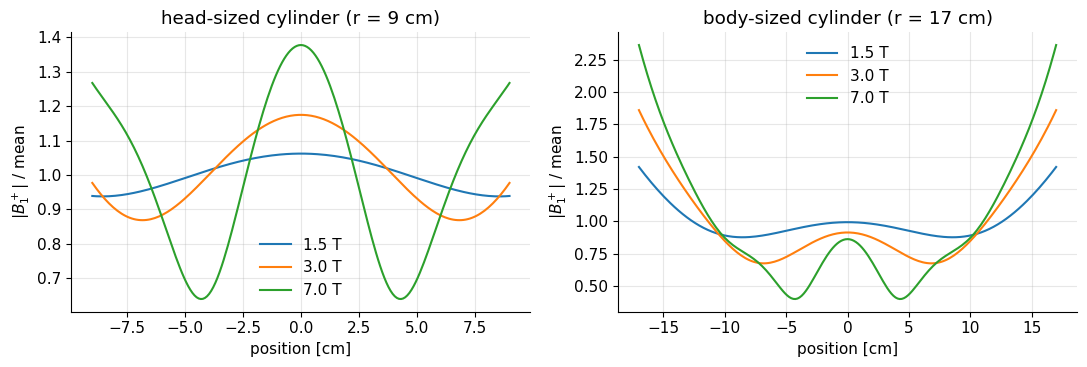

In [17]:
from scipy.special import jv
eps0 = 8.854e-12
tissue = {1.5: (72, 0.69), 3.0: (63, 0.72), 7.0: (58, 0.77)}     # approx. muscle-like (eps_r, sigma) at f0
rho = np.linspace(-1, 1, 201)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for B0_, (er, sg) in tissue.items():
    wv = 2 * np.pi * mt.larmor_frequency(B0_)
    kk = wv * np.sqrt(mt.MU0 * eps0 * (er - 1j * sg / (wv * eps0)))
    print(f"{B0_} T: f0 = {wv/2/np.pi/1e6:.0f} MHz, lambda_air = {3e8/(wv/2/np.pi):.2f} m, lambda_tissue = {2*np.pi/kk.real*100:.0f} cm")
    for axi, Rcyl in zip(ax, (0.09, 0.17)):
        prof = np.abs(jv(0, kk * rho * Rcyl)); axi.plot(rho * Rcyl * 100, prof / prof.mean(), label=f"{B0_} T")
for axi, title in zip(ax, ("head-sized cylinder (r = 9 cm)", "body-sized cylinder (r = 17 cm)")):
    axi.set(xlabel="position [cm]", ylabel=r"$|B_1^+|$ / mean", title=title); axi.legend()
plt.tight_layout(); plt.show()

At 1.5 T the field is fairly flat; at 3 T and 7 T it varies by tens of percent across the body — flip angles and image intensity follow ("dielectric shading", [I2 Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb)). In this lossy infinite-cylinder toy the conductivity dominates (darker centre); in real heads at 7 T the standing-wave effect produces the well-known **central brightening**.

> **TODO (polish):** replace the infinite-cylinder toy by a model reproducing 7 T central brightening (lower-loss brain properties, finite object) and add an 8-channel RF-shimming least-squares demo.

**Remedies:** high-permittivity **dielectric pads** (e.g. calcium/barium titanate suspensions) placed near the patient reshape $B_1^+$ locally; **RF shimming** drives the transmit channels of a multi-port coil with optimized complex weights $\mathbf w$ (minimize $\|\,|\mathbf A\mathbf w|-\text{target}\|$); **parallel transmit (pTx)** gives each channel its own waveform (see [J1 Excitation k-space](../pass2_deep_dive/J1_Excitation_K-space.ipynb)); adiabatic pulses are insensitive to $B_1$ ([J3](../pass2_deep_dive/J3_Fun_with_RF_Pulses.ipynb)).

### 8.2 SAR basics

The rotating $B_1$ induces electric fields (Faraday), which drive currents in conductive tissue and deposit power: $SAR=\sigma_{el}|\vec E|^2/\rho$ (with $|\vec E|$ the rms value). For a uniform rotating field of amplitude $B_1$ in a homogeneous sphere of radius $R_s$, the quasi-static field is $\vec E=-\tfrac12\dot{\vec B}\times\vec r$; averaging over time and volume gives

$$\overline{SAR}=\frac{\sigma_{el}\,\omega_0^2B_1^2R_s^2}{10\,\rho}.$$

In words: SAR grows with the **square** of the Larmor frequency (so with $B_0^2$), the square of $B_1$ (so with flip angle² / duration²), and the square of the body size.

<details><summary><b>📐 Derivation (optional)</b></summary>

$|\dot{\vec B}|=\omega_0B_1$ for a rotating field in the $xy$-plane. $|\dot{\vec B}\times\vec r|^2$ averaged over a rotation is $\omega_0^2B_1^2\,(z^2+(x^2+y^2)/2)$. Over a sphere $\langle x^2\rangle=\langle y^2\rangle=\langle z^2\rangle=R_s^2/5$, giving $\langle|\vec E|^2\rangle=\tfrac14\omega_0^2B_1^2\cdot\tfrac{2R_s^2}{5}=\omega_0^2B_1^2R_s^2/10$.

</details>

In [18]:
for B0_ in (1.5, 3.0, 7.0):
    wv = 2 * np.pi * mt.larmor_frequency(B0_)
    sar = 0.5 * wv**2 * (1e-6) ** 2 * 0.17**2 / (10 * 1000)
    print(f"{B0_} T: SAR per (uT)^2 of B1 (body-sized sphere, sigma 0.5 S/m) ≈ {sar:.2f} W/kg -> 2 W/kg at B1rms ≈ {np.sqrt(2/sar):.1f} uT")

1.5 T: SAR per (uT)^2 of B1 (body-sized sphere, sigma 0.5 S/m) ≈ 0.23 W/kg -> 2 W/kg at B1rms ≈ 2.9 uT
3.0 T: SAR per (uT)^2 of B1 (body-sized sphere, sigma 0.5 S/m) ≈ 0.93 W/kg -> 2 W/kg at B1rms ≈ 1.5 uT
7.0 T: SAR per (uT)^2 of B1 (body-sized sphere, sigma 0.5 S/m) ≈ 5.07 W/kg -> 2 W/kg at B1rms ≈ 0.6 uT


These order-of-magnitude numbers explain why SAR limits (2 W/kg whole body, [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb)) restrict refocusing-pulse-heavy sequences (fast spin echo) at 3 T and even more at 7 T.

### 8.3 RF shielding (Faraday cage)

The scanner room is a **Faraday cage** (copper or steel sheets, RF-tight door, filtered penetration panel, waveguides for tubes) attenuating outside RF by ~100 dB; an open door or a faulty device shows up as a "zipper" line in the image. Inside the magnet, an RF shield between gradient coil and body coil must block MHz but pass kHz gradient fields. Both rely on the **skin depth** $\delta_s=\sqrt{2/(\omega\mu_0\sigma_{el})}$:

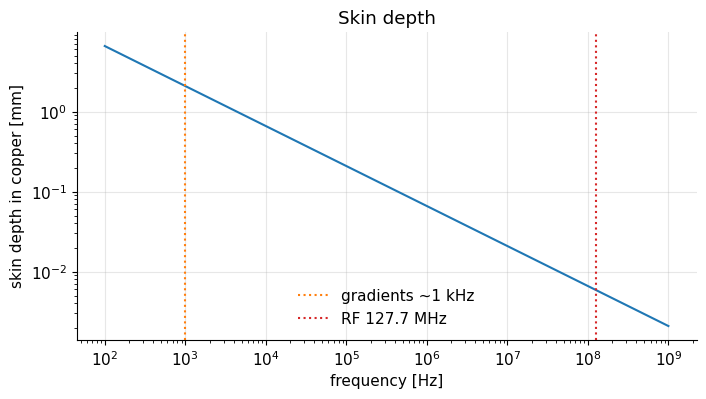

copper skin depth: 2.1 mm at 1 kHz, 5.8 um at 127.7 MHz


In [19]:
fq = np.logspace(2, 9, 200)
dskin = np.sqrt(2 / (2 * np.pi * fq * mt.MU0 * 5.8e7))
plt.loglog(fq, dskin * 1e3); plt.axvline(1e3, color="C1", ls=":", label="gradients ~1 kHz"); plt.axvline(127.7e6, color="C3", ls=":", label="RF 127.7 MHz")
plt.xlabel("frequency [Hz]"); plt.ylabel("skin depth in copper [mm]"); plt.legend(); plt.title("Skin depth"); plt.show()
print(f"copper skin depth: {np.sqrt(2/(2*np.pi*1e3*mt.MU0*5.8e7))*1e3:.1f} mm at 1 kHz, {np.sqrt(2/(2*np.pi*127.7e6*mt.MU0*5.8e7))*1e6:.1f} um at 127.7 MHz")

A few-µm skin depth means thin copper blocks RF completely; the inner RF shield is **slotted** (to stop eddy currents from gradients, which see a 2 mm skin depth) with capacitors bridging the slots — short circuits at MHz, open at kHz.

## Key takeaways

- Transmit: complex envelope → carrier at $f_0$ → kW amplifier → birdcage coil; quadrature drive of the degenerate $m=1$ mode produces a pure $B_1^+$ at half the power of linear drive.
- Receive coils are tuned LC resonators ($f=1/2\pi\sqrt{LC}$), matched to 50 Ω ($X_t=\sqrt{Z_0R}$); $Q_U/Q_L$ shows whether body noise dominates.
- Surface loops give high SNR near the surface (best radius ≈ depth/√5); arrays combine SNR and coverage using overlap and low-impedance preamp decoupling.
- Friis: the first stage sets the noise figure — preamps sit at the coil; PIN-diode traps detune receive coils during transmit.
- Quadrature demodulation = shift to the rotating frame; the ADC's bits must cover the k-space dynamic range.
- Thermal noise $\sqrt{4k_BTR\Delta f}$ (mostly from the patient) limits SNR; at high field the short wavelength in tissue causes $B_1^+$ inhomogeneity, and SAR grows as $B_0^2B_1^2$.

## Check your understanding

1. A loop has $L=200$ nH. What capacitance tunes it to 3 T (127.7 MHz)?

<details><summary>Answer</summary>

$C=1/(\omega^2L)=1/((2\pi\cdot127.7\times10^6)^2\cdot2\times10^{-7})\approx7.8$ pF.

</details>

2. $Q_U=250$, $Q_L=50$. What fraction of the noise comes from the patient?

<details><summary>Answer</summary>

$R_{sample}/R_{tot}=1-Q_L/Q_U=0.8$: 80 % — body-noise dominated.

</details>

3. Why does a linearly driven birdcage need twice the power of a quadrature-driven one for the same flip angle?

<details><summary>Answer</summary>

A linear field splits into two counter-rotating halves; only the co-rotating half ($B_1^+$) tips spins. Doubling the current (4× power) restores $B_1^+$; quadrature uses two ports with the original current (2× power) and puts all the field into $B_1^+$.

</details>

4. Compute the noise figure: preamp NF 1 dB, gain 20 dB, followed by a stage with NF 10 dB.

<details><summary>Answer</summary>

$F=1.259+(10-1)/100=1.349$ → NF = 1.30 dB.

</details>

5. Why can a single real demodulation channel not distinguish +2 kHz from −2 kHz?

<details><summary>Answer</summary>

$\cos(2\pi(f_0+\Delta f)t)\cos(2\pi f_0t)$ low-passed gives $\tfrac12\cos(2\pi\Delta ft)$, which is even in $\Delta f$. The sine (Q) channel provides the sign: $\tfrac12\sin(2\pi\Delta ft)$.

</details>

---
*New chapter written for this adaptation; see references below. Content on transmit/receive coils, birdcage, receive arrays, reciprocity, calibrations and dielectric shading was harvested from the original chapters "MRI System", "Magnetic Fields in MRI", "Signal to Noise Ratio" and "Artifacts" (P. Larson, "Principles of MRI", MIT License) and extended with circuit models and simulations.*

**References**
- J. Jin, *Electromagnetic Analysis and Design in Magnetic Resonance Imaging*, CRC Press, 1998 (birdcage theory).
- C. E. Hayes et al., "An efficient, highly homogeneous radiofrequency coil for whole-body NMR imaging at 1.5 T", *J. Magn. Reson.* 63, 622 (1985).
- P. B. Roemer, W. A. Edelstein, C. E. Hayes, S. P. Souza, O. M. Mueller, "The NMR phased array", *Magn. Reson. Med.* 16, 192 (1990).
- D. I. Hoult, R. E. Richards, "The signal-to-noise ratio of the nuclear magnetic resonance experiment", *J. Magn. Reson.* 24, 71 (1976).
- D. W. McRobbie et al., *MRI from Picture to Proton*, 3rd ed., Cambridge University Press, 2017.
- R. W. Brown et al., *Magnetic Resonance Imaging: Physical Principles and Sequence Design*, 2nd ed., Wiley, 2014.